# 01 · Pretraining a tabular in-context learner from scratch

TabPFN is used throughout this lab as a finished model: it reads a table of labeled rows and predicts new rows in one forward pass, with no training on the user's data. Everything it can do was fixed when it was pretrained, on millions of synthetic tables drawn from a hand-designed **prior**, a random generator of datasets. The prior is therefore where knowledge about a domain can enter such a model, and changing it is the lab's route to a model of its own: a prior that generates perturbation-biology tasks, for example from a simulator of gene regulatory networks, would pretrain a learner whose inference is tuned to that domain.

The TabPFN library this lab uses provides the trained model, its inference and its fine-tuning, but neither the prior nor the pretraining loop. This notebook builds the smallest complete version of both, following [nanoTabPFN](https://github.com/automl/nanoTabPFN) (Apache-2.0; [arXiv:2511.03634](https://arxiv.org/abs/2511.03634)), so that each part can be measured and later replaced. It asks three questions on two-feature classification problems small enough to pretrain on a laptop CPU, in about 40 minutes for the whole notebook on an idle machine:

1. Does a model pretrained only on synthetic tables learn in context at all, against classical learners fitted on the same labeled points?
2. How much does the **prior** matter: does pretraining on a richer family of datasets change what the model can do on problems inside and outside that family?
3. How much does **scale** matter, once the prior is fixed?

The [results page](docs/results/01-pretraining-from-scratch.md) repeats the pretraining runs over several seeds and records the numbers.

## What pretraining optimizes

A prior is a distribution $p(\mathcal{D})$ over datasets. One pretraining step draws a batch of datasets from it, splits each dataset $\mathcal{D}$ into labeled context rows $\mathcal{D}_{\mathrm{ctx}} = \{(x_i, y_i)\}_{i=1}^{n}$ and query rows, and asks the network $q_\theta$, with parameters $\theta$, for the label distribution of every query row $x_*$ given the context. The loss is the cross-entropy of the true query labels $y_*$:

$$
\mathcal{L}(\theta) = \mathbb{E}_{\mathcal{D} \sim p(\mathcal{D})} \left[ -\log q_\theta\left(y_* \mid x_*, \mathcal{D}_{\mathrm{ctx}}\right) \right].
$$

This loss is minimized when $q_\theta(y_* \mid x_*, \mathcal{D}_{\mathrm{ctx}})$ equals the posterior predictive distribution $p(y_* \mid x_*, \mathcal{D}_{\mathrm{ctx}})$ under the prior: the prediction a Bayesian would make if they knew the datasets came from $p(\mathcal{D})$. So a well-trained network does approximate Bayesian inference, but always with respect to the prior it was trained on. That is the sense in which the prior is the model's knowledge, and why the experiments below change it.

## 0. Setup

The model and the training loop are written out in this notebook. `helper.py` holds the device (the GPU when there is one, otherwise the CPU), three fixed evaluation problems the model never sees during pretraining, the classical learners used as references, and the plots.

In [1]:
import time

import torch
import torch.nn.functional as F
from torch import nn

from helper import (
    compare_with_baseline,
    count_parameters,
    device,
    evaluate_model,
    plot_predictions,
    plot_prior_samples,
)

# The results page reruns this notebook with SEED = 0, 1 and 2. Each pretraining run
# below starts from torch.manual_seed(SEED), so runs do not depend on what came before.
SEED = 0
torch.manual_seed(SEED)
print(f"device: {device}")
seconds = {}

device: cpu


## 1. A first prior: random straight boundaries

Every synthetic dataset has 50 rows and two features. A dataset is generated by drawing a boundary line $f(x_1) = a + b x_1$ with intercept $a$ and slope $b$ each drawn from a standard normal distribution, then 50 points with $x_1 \sim \mathcal{N}(0, 1)$ and $x_2 = f(x_1) + \varepsilon$, $\varepsilon \sim \mathcal{N}(0, 1)$, so the points scatter around the line. A point's label is 1 when it lies above the line and 0 below, with a small Gaussian perturbation of standard deviation 0.1 that blurs labels right at the boundary. The first $n$ rows of each dataset are the labeled context, with $n$ drawn anew for each batch between 10 and 47, and the remaining rows are the queries.

The function also returns each dataset's boundary, used only for plotting.

In [2]:
def sample_from_prior(batch_size, num_rows=50, noise_std=0.1):
    '''A batch of synthetic tables with two features x1 and x2:
    class 1 above a random boundary line, class 0 below it.'''
    # boundary x2 = a + b*x1, one per table
    a = torch.randn(batch_size, 1)  # intercept ~ N(0, 1)
    b = torch.randn(batch_size, 1)  # slope ~ N(0, 1)
    boundary = lambda t: a + b * t
    # points scattered around the boundary
    x1 = torch.randn(batch_size, num_rows)
    x2 = boundary(x1) + torch.randn(batch_size, num_rows)
    # class 1 above the boundary, class 0 below (slightly noisy)
    noise = noise_std * torch.randn(batch_size, num_rows)
    y = (x2 + noise > boundary(x1)).float()
    # the first n_train rows are labeled, the model predicts the rest
    n_train = torch.randint(10, num_rows - 2, ()).item()
    # the boundary is returned only for plotting
    return torch.stack([x1, x2], dim=-1), y, n_train, boundary

Four datasets from this prior, each with its true boundary dashed:

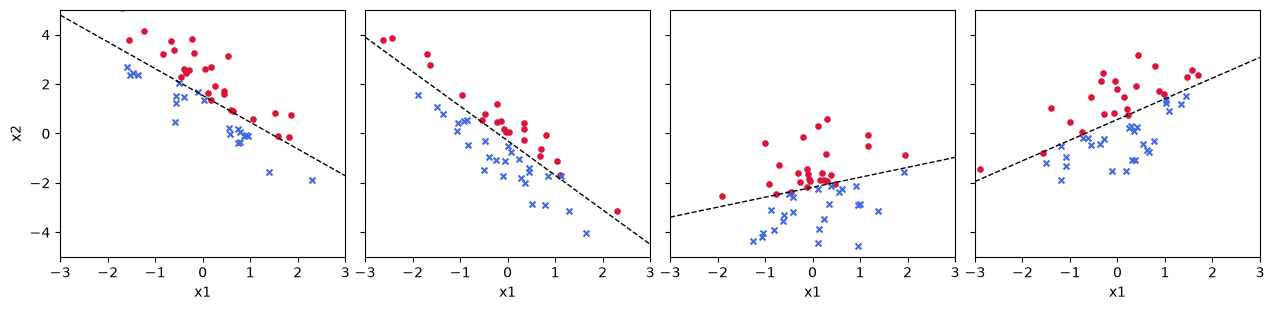

In [3]:
x, y, n_train, boundary = sample_from_prior(4)
plot_prior_samples(x, y, boundary)

## 2. The model: attention across features and across rows

A table enters the model cell by cell. Each feature value is mapped by a small linear layer to a vector of length $E$, the embedding width, so a batch of tables becomes a tensor of shape (batch, rows, columns, $E$). The label is appended as one more column: classes 0 and 1 are encoded as $-1$ and $+1$, which leaves $0$ free to mean "unknown" in the query rows, whose label the model must supply.

Each layer then mixes information in two directions:

- **across the features of a row**: the cells of one row attend to each other, so a row's representation can combine its features, including its label cell;
- **across the rows of a column**: every row, labeled or not, attends to the labeled rows of the same column, so a query row can gather what the context says about rows like it.

Neither direction has a positional encoding, so the model treats both the columns and the rows of a table as unordered sets, which is what a table is. After the last layer, the label cell of each query row is decoded into two logits, and their softmax is the predicted class probability.

Before embedding, each feature is standardized with the mean and standard deviation of the labeled rows of its own dataset, so the model sees every table on a comparable scale.

In [4]:
class TransformerLayer(nn.Module):
    '''Attention between features (within a row), attention between
    datapoints (within a column), then an MLP.'''

    def __init__(self, emb, heads):
        super().__init__()
        self.attn_features = nn.MultiheadAttention(
            emb, heads, batch_first=True)
        self.attn_datapoints = nn.MultiheadAttention(
            emb, heads, batch_first=True)
        self.mlp = nn.Sequential(
            nn.Linear(emb, 4 * emb), nn.GELU(), nn.Linear(4 * emb, emb))
        self.norm1 = nn.LayerNorm(emb)
        self.norm2 = nn.LayerNorm(emb)
        self.norm3 = nn.LayerNorm(emb)

    def forward(self, h, n_train):
        B, R, C, E = h.shape  # (batch, rows, columns, embedding)
        # self-attention over the features of each row:
        # fold the row dimension into the batch dimension
        h = h.reshape(B * R, C, E)
        h = self.norm1(h + self.attn_features(h, h, h)[0])
        h = h.reshape(B, R, C, E)
        # attention over the rows of each column:
        # fold the column dimension into the batch dimension;
        # all rows attend to the labeled rows only
        h = h.transpose(1, 2).reshape(B * C, R, E)
        labeled = h[:, :n_train]
        h = self.norm2(h + self.attn_datapoints(h, labeled, labeled)[0])
        h = h.reshape(B, C, R, E).transpose(1, 2)
        return self.norm3(h + self.mlp(h))

In [5]:
class NanoTabPFN(nn.Module):
    def __init__(self, emb, layers, heads=4, num_classes=2):
        super().__init__()
        self.x_encoder = nn.Linear(1, emb)  # embeds each feature cell
        self.y_encoder = nn.Linear(1, emb)  # embeds each label cell
        self.layers = nn.ModuleList(
            [TransformerLayer(emb, heads) for _ in range(layers)])
        self.decoder = nn.Sequential(
            nn.Linear(emb, 4 * emb), nn.GELU(),
            nn.Linear(4 * emb, num_classes))

    def forward(self, x_train, y_train, x_test):
        # x_train: (B, n_train, features), y_train: (B, n_train),
        # x_test: (B, n_test, features)
        n_train = x_train.shape[1]
        # standardize each feature using the labeled rows
        mean = x_train.mean(1, keepdim=True)
        std = x_train.std(1, keepdim=True)
        x = torch.cat([x_train, x_test], dim=1)  # (B, rows, features)
        x = (x - mean) / (std + 1e-8)
        # classes 0 / 1 enter as -1 / +1; unknown test labels as 0
        y = F.pad(2 * y_train - 1, (0, x_test.shape[1]))
        # embed every cell (one number) as a vector of length emb
        x_emb = self.x_encoder(x.unsqueeze(-1))  # (B, rows, features, emb)
        # the label column: (B, rows, 1, emb)
        y_emb = self.y_encoder(y.unsqueeze(-1)).unsqueeze(2)
        h = torch.cat([x_emb, y_emb], dim=2)  # the label: one more column
        for layer in self.layers:
            h = layer(h, n_train)  # (B, rows, features + 1, emb)
        # class logits from the label cell of every test row
        return self.decoder(h[:, n_train:, -1])

## 3. The pretraining loop

Each step draws 32 fresh datasets from the prior, so the model never sees the same table twice, feeds it the labeled rows, and scores its predicted probabilities on the query rows with the cross-entropy above. The learning rate decays to zero along a cosine schedule. Every tenth of the run, the loop logs the mean accuracy on the three evaluation problems in `helper.py`, which the model never trains on:

| Problem | Boundary $f(x_1)$ | Inside the line prior | Inside the wave prior (section 4) |
|---|---|---|---|
| line | $0.3 + 0.8 x_1$ | yes | yes |
| sine | $1.5 \sin(1.5 x_1)$ | no | yes |
| sine + fast wave | $\sin(1.5 x_1) + 0.6 \sin(4 x_1)$ | no | no |

Each problem is scored over 20 fixed draws of 40 labeled points and 200 query points, the same draws for every model.

In [6]:
def train(model, num_steps, lr, batch_size=32):
    model = model.to(device)  # run on the GPU if there is one
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_steps)
    t0 = time.time()
    for step in range(1, num_steps + 1):
        # fresh synthetic tables every step
        x, y, n_train, _ = sample_from_prior(batch_size)
        x, y = x.to(device), y.to(device)
        # split into labeled (train) and unlabeled (test) rows
        x_train, x_test = x[:, :n_train], x[:, n_train:]
        y_train, y_test = y[:, :n_train], y[:, n_train:]
        logits = model(x_train, y_train, x_test)
        # only the unlabeled rows are scored
        loss = F.cross_entropy(
            logits.reshape(-1, 2), y_test.reshape(-1).long())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        if step % (num_steps // 10) == 0:
            seconds = time.time() - t0
            acc = evaluate_model(model)
            print(f"step {step:4d} | {seconds:5.1f}s | "
                  f"loss {loss.item():6.3f} | test accuracy {acc:.3f}")
    return model

### A small model on the line prior

Embedding width 48, two layers, 750 steps.

In [7]:
torch.manual_seed(SEED)
t0 = time.time()
small_lines = train(NanoTabPFN(emb=48, layers=2), num_steps=750, lr=1e-3)
seconds["small, line prior"] = time.time() - t0
print(f"{count_parameters(small_lines):,} parameters")

step   75 |  37.3s | loss  0.378 | test accuracy 0.688


step  150 |  60.5s | loss  0.181 | test accuracy 0.852


step  225 |  82.0s | loss  0.175 | test accuracy 0.860


step  300 | 109.7s | loss  0.180 | test accuracy 0.850


step  375 | 145.6s | loss  0.133 | test accuracy 0.856


step  450 | 181.3s | loss  0.128 | test accuracy 0.857


step  525 | 214.8s | loss  0.188 | test accuracy 0.857


step  600 | 267.5s | loss  0.160 | test accuracy 0.854


step  675 | 341.1s | loss  0.160 | test accuracy 0.856


step  750 | 407.8s | loss  0.151 | test accuracy 0.855


85,538 parameters


Below, the model's predicted probability of class 1 over the whole plane, for the first draw of each evaluation problem: red for class 1, blue for class 0, white where the model is undecided. The 40 markers are the labeled points it reads as context, and the dashed curve is the true boundary. A model pretrained only on straight boundaries can only draw something close to a straight boundary.

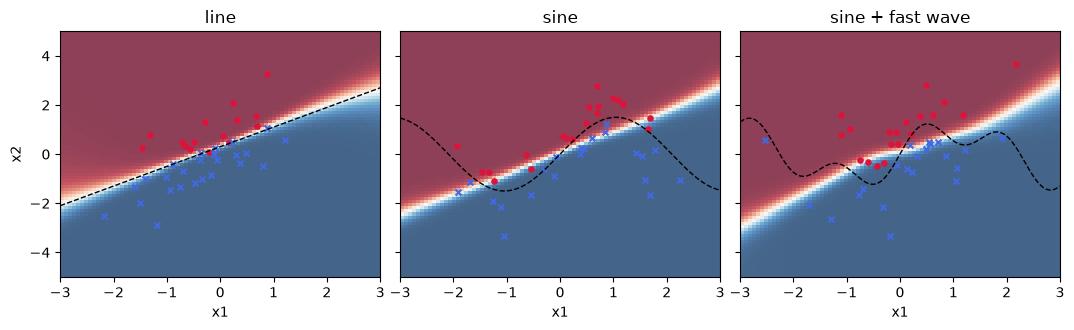

In [8]:
plot_predictions(small_lines)

The same draws scored for the pretrained model and for two classical learners fitted directly on each draw's 40 labeled points: a logistic regression, which can only draw a straight boundary, and a random forest of 100 trees, which can draw any boundary but has only 40 points to find it.

In [9]:
compare_with_baseline({"small, line prior": small_lines})

,line,sine,sine + fast wave,mean
"small, line prior",0.960,0.805,0.799,0.855
logistic regression,0.940,0.776,0.798,0.838
random forest,0.862,0.827,0.846,0.845


## 4. A richer prior: waves on the line

The prior is the only thing that changes now. Each boundary gains a sine wave, $f(x_1) = a + b x_1 + A \sin(\omega x_1 + \varphi)$, with amplitude $A$ uniform on $[0, 2]$, angular frequency $\omega$ uniform on $[0.5, 5]$ and phase $\varphi$ uniform on $[0, 2\pi]$. When $A$ is small the boundary is nearly straight, so the new family includes, in the limit, the old one.

In [10]:
def sample_from_prior(batch_size, num_rows=50, noise_std=0.1):
    '''A batch of synthetic tables with two features x1 and x2:
    class 1 above a random boundary curve, class 0 below it.'''
    # boundary x2 = a + b*x1 + A*sin(w*x1 + phi), one per table
    a = torch.randn(batch_size, 1)                  # intercept ~ N(0, 1)
    b = torch.randn(batch_size, 1)                  # slope ~ N(0, 1)
    amp = 2 * torch.rand(batch_size, 1)             # amplitude ~ U(0, 2)
    w = 0.5 + 4.5 * torch.rand(batch_size, 1)       # frequency ~ U(0.5, 5)
    phi = 2 * torch.pi * torch.rand(batch_size, 1)  # phase ~ U(0, 2 pi)
    boundary = lambda t: a + b * t + amp * torch.sin(w * t + phi)
    # points scattered around the boundary
    x1 = torch.randn(batch_size, num_rows)
    x2 = boundary(x1) + torch.randn(batch_size, num_rows)
    # class 1 above the boundary, class 0 below (slightly noisy)
    noise = noise_std * torch.randn(batch_size, num_rows)
    y = (x2 + noise > boundary(x1)).float()
    # the first n_train rows are labeled, the model predicts the rest
    n_train = torch.randint(10, num_rows - 2, ()).item()
    # the boundary is returned only for plotting
    return torch.stack([x1, x2], dim=-1), y, n_train, boundary

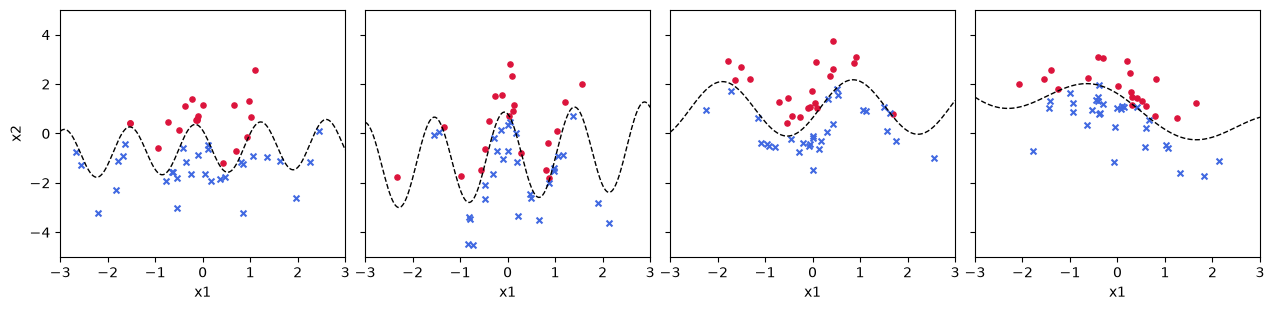

In [11]:
x, y, n_train, boundary = sample_from_prior(4)
plot_prior_samples(x, y, boundary)

The same architecture, size and number of steps as before, on the new prior:

In [12]:
torch.manual_seed(SEED)
t0 = time.time()
small = train(NanoTabPFN(emb=48, layers=2), num_steps=750, lr=1e-3)
seconds["small, wave prior"] = time.time() - t0

step   75 |  50.3s | loss  0.596 | test accuracy 0.626


step  150 | 111.1s | loss  0.426 | test accuracy 0.864


step  225 | 192.1s | loss  0.380 | test accuracy 0.872


step  300 | 349.0s | loss  0.389 | test accuracy 0.880


step  375 | 533.1s | loss  0.368 | test accuracy 0.894


step  450 | 644.8s | loss  0.388 | test accuracy 0.895


step  525 | 729.1s | loss  0.431 | test accuracy 0.902


step  600 | 827.5s | loss  0.361 | test accuracy 0.900


step  675 | 906.3s | loss  0.295 | test accuracy 0.906


step  750 | 983.4s | loss  0.254 | test accuracy 0.907


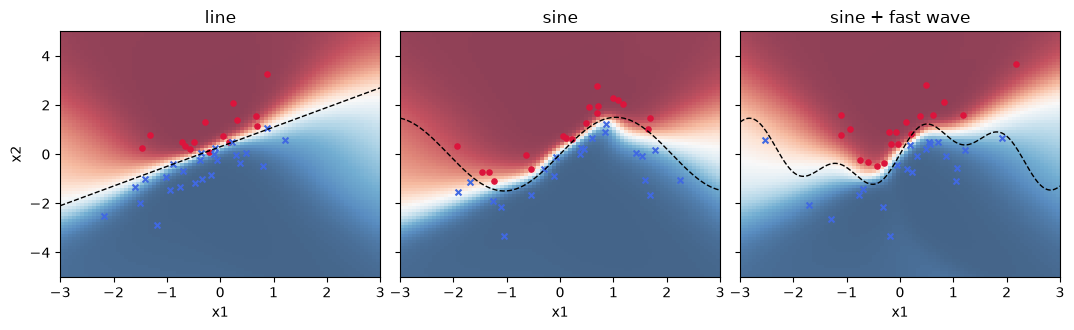

In [13]:
plot_predictions(small)

In [14]:
compare_with_baseline({"small, line prior": small_lines, "small, wave prior": small})

,line,sine,sine + fast wave,mean
"small, line prior",0.960,0.805,0.799,0.855
"small, wave prior",0.949,0.888,0.885,0.907
logistic regression,0.940,0.776,0.798,0.838
random forest,0.862,0.827,0.846,0.845


## 5. Scale, with the prior fixed

Three knobs at once: embedding width 48 to 96, two layers to three, 750 steps to 2,500. This is the expensive run: about half an hour on an idle laptop CPU, against a few minutes for each small run, and a few minutes on a GPU. The elapsed times in the training logs below are wall-clock times, so they grow when the machine is busy with other work; they are not a measurement of the model.

In [15]:
torch.manual_seed(SEED)
t0 = time.time()
large = train(NanoTabPFN(emb=96, layers=3), num_steps=2500, lr=1e-3)
seconds["large, wave prior"] = time.time() - t0
print(f"{count_parameters(large):,} parameters")

step  250 | 655.9s | loss  0.262 | test accuracy 0.905


step  500 | 959.5s | loss  0.360 | test accuracy 0.908


step  750 | 1302.3s | loss  0.233 | test accuracy 0.920


step 1000 | 1503.1s | loss  0.313 | test accuracy 0.918


step 1250 | 1689.0s | loss  0.187 | test accuracy 0.926


step 1500 | 1903.8s | loss  0.266 | test accuracy 0.924


step 1750 | 2159.0s | loss  0.151 | test accuracy 0.926


step 2000 | 2328.3s | loss  0.257 | test accuracy 0.927


step 2250 | 9682.8s | loss  0.229 | test accuracy 0.930


step 2500 | 10580.9s | loss  0.212 | test accuracy 0.929
486,242 parameters


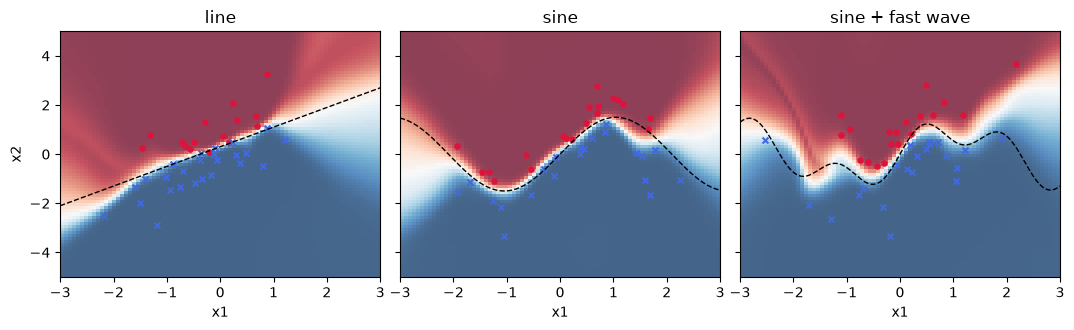

In [16]:
plot_predictions(large)

In [17]:
compare_with_baseline({"small, wave prior": small, "large, wave prior": large})

,line,sine,sine + fast wave,mean
"small, wave prior",0.949,0.888,0.885,0.907
"large, wave prior",0.951,0.920,0.917,0.930
logistic regression,0.940,0.776,0.798,0.838
random forest,0.862,0.827,0.846,0.845


## What this establishes, and what it opens

- **In-context learning can be pretrained from synthetic data alone.** A network that has never seen the evaluation problems classifies their query points from 40 labeled examples, in one forward pass and without any fitting.
- **The prior bounds what the model can infer.** Pretrained on straight boundaries, the model draws straight boundaries; pretrained on waves, the same architecture follows curved ones. The prior acts like an inductive bias that is learned rather than built into the architecture.
- **Scale helps within the prior.** A wider, deeper model trained longer follows the curved boundaries more closely; how much it helps on the problem outside both priors is the more telling number, recorded on the results page.

For this lab, the parts are now in hand to put a domain into the prior: replace `sample_from_prior` with a generator of tasks from a simulator of perturbation biology, keep the model and the loop, and measure the result on the lab's own endpoints against TabPFN, which knows nothing of that domain. The numbers on the results page set the scale of what a prior can change, and what scale alone can.

The last cell writes this run's scores, on every evaluation draw, to the report the results page aggregates.

In [18]:
import json
import platform
from pathlib import Path

from helper import BASELINES, EVAL_SEED, N_CONTEXT, N_DRAWS, N_QUERY, accuracy_per_draw, baseline_accuracy_per_draw

models = {"small, line prior": small_lines, "small, wave prior": small, "large, wave prior": large}
report = {
    "notebook": "01_pretraining_from_scratch.ipynb",
    "seed": SEED,
    "evaluation": {"n_context": N_CONTEXT, "n_query": N_QUERY, "n_draws": N_DRAWS, "seed": EVAL_SEED},
    "models": {
        name: {"parameters": count_parameters(m), "train_seconds": round(seconds[name], 1),
               "accuracy_per_draw": accuracy_per_draw(m)}
        for name, m in models.items()
    },
    "baselines": {name: {"accuracy_per_draw": baseline_accuracy_per_draw(name)} for name in BASELINES},
    "environment": {"device": str(device), "torch": torch.__version__, "python": platform.python_version(),
                    "machine": f"{platform.system()} {platform.machine()}", "threads": torch.get_num_threads()},
}
path = Path(f"docs/results/reports/01-pretraining-from-scratch-seed{SEED}.json")
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(report, indent=1))
print(f"wrote {path}")

wrote docs/results/reports/01-pretraining-from-scratch-seed0.json
